# JERICHON — AFML 05: PCA, DBSCAN, LDA и рыночные режимы

**Цель:** проверить новые способы представления признаков и поиска режимов рынка на одной и той же разметке, с хронологическим разделением и целевой метрикой F1.

Методы:
1. **Контрольная модель:** Random Forest на исходных признаках.
2. **PCA + Random Forest:** сжатие признаков без использования целевой переменной.
3. **PCA + DBSCAN + Random Forest:** добавление найденного кластера/шума как признака режима. DBSCAN не умеет штатно назначать кластер новым наблюдениям, поэтому для теста используется явное правило ближайшего ядра внутри радиуса eps.
4. **LDA + Logistic Regression:** контролируемое линейное сжатие, использующее метки только обучающей части.
5. **Отбор по взаимной информации + Random Forest:** дополнительная идея №1 — оставить только признаки, наиболее связанные с целью.
6. **Признаки волатильности + Random Forest:** дополнительная идея №2 — проверить отдельно вклад уже существующих признаков, названия которых указывают на волатильность, и сравнить с полной моделью.

**Важно:** кластеризация сама по себе не знает, какой кластер прибыльный или лучше предсказывает цель. Проверяем это только по будущим меткам. Все преобразования обучаются только на прошлом. Финальные 20% не используются для выбора метода.

Ноутбук строит канонический набор 474 признаков через локальный `jerichon_feature_pipeline.py`. Он не обращается к API и не изменяет исходные файлы.


## 1. Подготовка локальных данных

Ниже сохранён этап чтения локальной истории AlgoPack и построения 474 признаков из исходного notebook. Он не обращается к API и не меняет исходные файлы.


In [2]:
# Конфигурация и импорты. Источники — только локальные файлы AlgoPack; API не вызывается.
from pathlib import Path
import os, sys, inspect, warnings, json, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.cluster import DBSCAN
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import f1_score, balanced_accuracy_score, precision_score, recall_score, confusion_matrix, classification_report
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

TICKER = "MAGN"  # Меняй на GAZP, SPBE, MTLR, YDEX; один тикер за запуск
DOLLAR_THRESHOLD = 10_000_000
MSK = "Europe/Moscow"
CUSUM_THRESHOLD = 0.001
PT_SL = (1.0, 1.0)
VERTICAL_HORIZON = 50
TARGET_WINDOW = 55
EXPECTED_FEATURES = 474
SEED = 63

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную."
    )

ROOT = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data")
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
HISTORY_ROOT = ROOT / "for_ml" / "storage" / "history"

from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder
from src.data.builders import jerichon_feature_pipeline as jfp

print("Тикер:", TICKER)
print("Каталог истории:", HISTORY_ROOT)
print("Pipeline:", Path(inspect.getfile(jfp)).resolve())


ModuleNotFoundError: No module named 'src.data'

## 1. Загрузка локальной истории

Формат путей сохранён **как в `jerichon_mark_63(3).ipynb`**:

- `data/for_ml/storage/history/realtime/{TICKER}/{YYYY-MM-DD}/trades.parquet`
- `data/for_ml/storage/history/supercandles/{TICKER}/{YYYY-MM-DD}/{tradestats,obstats,orderstats}.parquet`

Файлы только читаются. Если какой-то источник отсутствует, notebook покажет это явно.

In [4]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)

    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")

    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    print(f"Saved dates discovered: {len(dates)}")
    print(f"Date range            : {dates[0]} → {dates[-1]}")
    print("\\nLocal rows:")
    display(pd.DataFrame({"source": list(out), "rows": [len(out[k]) for k in out]}))
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников: {missing}. API-запрос не будет выполняться.")
    return out, dates

data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

Saved dates discovered: 18
Date range            : 2026-09-25 → 2026-10-27
\nLocal rows:


,source,rows
0,candles,16094
1,trades,701991
2,orderbook,360
3,tradestats,3250
4,obstats,3160
5,orderstats,3268


## 2. Построение Dollar Bars и 474 признаков

Используем подготовленный модуль `jerichon_feature_pipeline.py`, а не копируем его инженерный код в notebook. Важно: **не вызываем** публичный `build_feature_dataset()`, если он сам создаёт `AlgoPackProvider`; вместо этого вызываем локальные функции модуля над уже прочитанными DataFrame.

Если локальная версия модуля не содержит ожидаемые helper-функции, выполнение остановится с понятной ошибкой, а не отправит запрос в API.

In [5]:
# Сначала проверяем интерфейс установленного файла — никаких сетевых вызовов здесь нет.
required_helpers = (
    "_trades_for_bars",
    "build_dollar_bars_from_trades",
    "_base",
    "_build_sc_features",
    "_choose_availability",
    "_attach_source",
)
missing_helpers = [name for name in required_helpers if not hasattr(jfp, name)]
if missing_helpers:
    raise RuntimeError(
        "В установленном jerichon_feature_pipeline.py не найдены helper-функции: "
        f"{missing_helpers}. Проверь, что в проекте стоит актуальная версия pipeline. "
        "Этот notebook намеренно не переключается на API."
    )

print("Helper signatures:")
for name in required_helpers:
    print(f"  {name}{inspect.signature(getattr(jfp, name))}")

Helper signatures:
  _trades_for_bars(trades)
  build_dollar_bars_from_trades(trades, threshold=13000000)
  _base(bars)
  _build_sc_features(raw_sources, bars_for_features)
  _choose_availability(df, source_name)
  _attach_source(bars, feature_frame, raw_source, source)


In [6]:
# Dollar Bars: используем тот же денежный объём VALUE / PRICE, что и в reference.
bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
if bars is None or bars.empty:
    raise RuntimeError("Dollar Bar builder вернул пустой результат.")

# Унифицируем имя времени для последующих causal joins.
if "bar_ts" not in bars.columns:
    if "close_time" not in bars.columns:
        raise RuntimeError(f"В bars нет bar_ts/close_time. Колонки: {list(bars.columns)}")
    bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
else:
    bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)

bars = (bars.dropna(subset=["bar_ts"])
             .sort_values("bar_ts")
             .drop_duplicates("bar_ts", keep="last")
             .reset_index(drop=True))

print("Dollar Bars:", len(bars))
print("Period:", bars["bar_ts"].min(), "→", bars["bar_ts"].max())
display(bars.head(3))

Dollar Bars: 3042
Period: 2026-09-25 04:03:05+00:00 → 2026-10-27 18:00:30+00:00


,open,high,low,close,volume,value,count,open_time,close_time,bar_ts
0,251.2,252.2,251.0,252.2,40061.0,10074986.8,213,2026-09-25 03:59:54+00:00,2026-09-25 04:03:05+00:00,2026-09-25 04:03:05+00:00
1,252.0,252.2,251.0,251.6,40150.0,10095034.2,249,2026-09-25 04:03:05+00:00,2026-09-25 04:16:20+00:00,2026-09-25 04:16:20+00:00
2,251.6,251.8,250.6,251.0,39839.0,10011897.2,276,2026-09-25 04:16:20+00:00,2026-09-25 04:33:18+00:00,2026-09-25 04:33:18+00:00


In [7]:
# Base 73 + Super Candle 401. Работаем через helper-функции pipeline.
base_raw = jfp._base(bars.copy())
if isinstance(base_raw, tuple):
    # Поддержка версий helper, возвращающих (features, metadata).
    base_raw = base_raw[0]
if not isinstance(base_raw, pd.DataFrame):
    raise TypeError(f"_base должен вернуть DataFrame, получено: {type(base_raw)}")

# Приводим base frame к контракту bar_ts + 73 числовых признака.
if "bar_ts" not in base_raw.columns:
    if "close_time" in base_raw.columns:
        base_raw = base_raw.rename(columns={"close_time": "bar_ts"})
    elif isinstance(base_raw.index, pd.DatetimeIndex):
        base_raw = base_raw.reset_index().rename(columns={base_raw.index.name or "index": "bar_ts"})
    elif "ts" in base_raw.columns:
        base_raw = base_raw.rename(columns={"ts": "bar_ts"})
    else:
        raise RuntimeError(f"Не найден временной ключ в _base output. Колонки: {list(base_raw.columns)[:25]}")

base_raw["bar_ts"] = pd.to_datetime(base_raw["bar_ts"], errors="coerce", utc=True)
base_raw = base_raw.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

# _build_sc_features может возвращать feature_frames либо (feature_frames, groups).
# Адаптируем Dollar Bars к формату, ожидаемому pipeline.
bars_for_sc = bars.copy()

# В pipeline ожидаются ts и CLOSE.
if "ts" not in bars_for_sc.columns:
    if "bar_ts" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    elif "close_time" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["close_time"]
    else:
        raise KeyError("В bars отсутствует временная колонка ts/bar_ts/close_time")

if "CLOSE" not in bars_for_sc.columns:
    if "close" in bars_for_sc.columns:
        bars_for_sc["CLOSE"] = bars_for_sc["close"]
    else:
        raise KeyError("В bars отсутствует цена закрытия CLOSE/close")

bars_for_sc["ts"] = pd.to_datetime(bars_for_sc["ts"], errors="coerce", utc=True)

bars_for_sc = (
    bars_for_sc.dropna(subset=["ts"])
    .sort_values("ts")
    .reset_index(drop=True))

sc_result = jfp._build_sc_features(data, bars_for_sc)

if isinstance(sc_result, tuple):
    feature_frames = sc_result[0]
    feature_groups = sc_result[1] if len(sc_result) > 1 else {}
else:
    feature_frames = sc_result
    feature_groups = {}

if not isinstance(feature_frames, dict):
    raise TypeError("_build_sc_features должен возвращать dict feature frames.")

print("Base output shape:", base_raw.shape)
print("Super Candle feature groups:", list(feature_frames))

Base output shape: (3042, 74)
Super Candle feature groups: ['tradestats', 'orderstats', 'obstats']


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

In [8]:
# Availability validation and causal joins, source by source.
# Helpers' outputs are inspected to support the current prepared module contract.
validated = {}
availability_diagnostics = []

for source in ("tradestats", "obstats", "orderstats"):
    if data[source].empty:
        raise RuntimeError(f"Локальный источник {source} пуст.")

    result = jfp._choose_availability(data[source].copy(), source)
    if isinstance(result, tuple):
        validated[source] = result[0]
        if len(result) > 1 and isinstance(result[1], pd.DataFrame):
            availability_diagnostics.append(result[1])
    else:
        validated[source] = result

print("Validated sources:")
for source, frame in validated.items():
    print(f"  {source:12s}: {len(frame):,} rows, columns={len(frame.columns)}")

if availability_diagnostics:
    display(pd.concat(availability_diagnostics, ignore_index=True))

Validated sources:
  tradestats  : 3,250 rows, columns=2
  obstats     : 3,160 rows, columns=2
  orderstats  : 3,268 rows, columns=2


In [9]:
# Normalize the bars frame for the pipeline's attach helper.
bar_frame = bars.copy()
if "bar_ts" not in bar_frame.columns:
    raise RuntimeError("bar_ts missing from Dollar Bars.")

# Resolve each raw source to the corresponding feature frame by name.
def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source} с feature frame. Доступны: {list(frames)}")

causal = bar_frame.copy()
for source in ("tradestats", "obstats", "orderstats"):
    feature_frame = resolve_feature_frame(source, feature_frames)
    
    # ИСПРАВЛЕНО: правильный порядок аргументов + исходные данные вместо validated
    attached = jfp._attach_source(causal, feature_frame, data[source], source)
    
    # Поддержка helper, возвращающего либо изменённый frame, либо None in-place.
    if isinstance(attached, pd.DataFrame):
        causal = attached
    print(f"{source:12s} attached → {causal.shape}")

# Добавляем base features по точному bar_ts.
base_cols = [c for c in base_raw.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base_raw[c])]
if len(base_cols) != 73:
    raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}.")

base_join = base_raw[["bar_ts"] + base_cols].copy()
base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols})
base_cols = [c for c in base_join.columns if c.startswith("base__")]

if "bar_ts" not in causal.columns:
    raise RuntimeError(f"После causal join нет bar_ts. Колонки: {list(causal.columns)[:30]}")

causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
base_join["bar_ts"] = pd.to_datetime(base_join["bar_ts"], errors="coerce", utc=True)
causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

# Identify features and provenance without admitting timestamps into X.
time_cols = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
provenance_cols = [
    c for c in causal.columns
    if c.endswith("__event_ts") or c.endswith("__available_at")
]
sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
sc_feature_cols = [
    c for c in causal.columns
    if c.startswith(sc_prefixes)
    and c not in provenance_cols
    and pd.api.types.is_numeric_dtype(causal[c])
]
# Не включаем сырые OHLCV/служебные колонки из bars: только канонические 73 + 401.
feature_cols = base_cols + sc_feature_cols

if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(
        f"Feature inventory mismatch: {len(feature_cols)} numeric ML features, expected {EXPECTED_FEATURES}. "
        "Не продолжаем обучение на непроверенной матрице."
    )

if len(feature_cols) != len(set(feature_cols)):
    raise RuntimeError("Есть дублирующиеся имена признаков.")

FINAL_DATASET = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
FINAL_DATASET = FINAL_DATASET.sort_values("bar_ts").reset_index(drop=True)
X_raw = FINAL_DATASET[feature_cols].copy()

print("FINAL_DATASET:", FINAL_DATASET.shape)
print("Rows:", len(FINAL_DATASET))
print("ML features:", len(feature_cols))
print("Provenance columns:", len(provenance_cols))

tradestats   attached → (3042, 106)
obstats      attached → (3042, 244)
orderstats   attached → (3042, 417)
FINAL_DATASET: (3042, 481)
Rows: 3042
ML features: 474
Provenance columns: 6


## 3. Temporal Audit — статус PASSED

По предыдущей диагностике пользователя статус Temporal Audit = `PASSED`. В этом исследовании не повторяем полный аудит доступности: дальше работаем над моделями и торговой проверкой. Оставляем только короткую проверку контракта provenance, чтобы notebook не продолжил работу, если обязательные поля неожиданно отсутствуют.

In [10]:
# Lightweight prerequisite check only; this does not rerun the already-passed temporal audit.
required_provenance = [
    f"{source}__available_at" for source in ("tradestats", "obstats", "orderstats")
] + [
    f"{source}__event_ts" for source in ("tradestats", "obstats", "orderstats")
]
missing_provenance = [col for col in required_provenance if col not in FINAL_DATASET.columns]
if missing_provenance:
    raise RuntimeError(f"Temporal Audit prerequisite missing provenance columns: {missing_provenance}")
TEMPORAL_AUDIT_STATUS = "PASSED (previously confirmed; full audit not rerun in this research notebook)"
print(TEMPORAL_AUDIT_STATUS)
print("Provenance columns present:", len(required_provenance))

PASSED (previously confirmed; full audit not rerun in this research notebook)
Provenance columns present: 6


## 4. Проверка качества признаков

Нулевые значения не удаляем автоматически. Важные показатели:
- `NaN` и `±inf` по каждому признаку;
- доля нулей (диагностика, не критерий удаления);
- константные признаки;
- полностью пустые признаки;
- дублирующиеся строки и timestamps.

Исходный `FINAL_DATASET` не перезаписывается. Для модели создаётся отдельная копия, в которой бесконечности переводятся в `NaN`; далее imputer обучается только на train.

In [11]:
X_num = X_raw.apply(pd.to_numeric, errors="coerce")
arr = X_num.to_numpy(dtype="float64", copy=True)
finite_mask = np.isfinite(arr)

quality = pd.DataFrame(index=X_num.columns)
quality["missing_pct"] = X_num.isna().mean() * 100
quality["positive_inf"] = np.isposinf(arr).sum(axis=0)
quality["negative_inf"] = np.isneginf(arr).sum(axis=0)
quality["zero_pct"] = (X_num.eq(0).mean() * 100)
quality["unique_values"] = X_num.nunique(dropna=True)
quality["all_missing"] = X_num.isna().all()
quality["constant_or_single_value"] = quality["unique_values"] <= 1
quality["non_finite_total"] = quality["positive_inf"] + quality["negative_inf"]

print("Rows:", len(X_num), "| features:", X_num.shape[1])
print("NaN cells:", int(X_num.isna().sum().sum()))
print("+inf cells:", int(np.isposinf(arr).sum()))
print("-inf cells:", int(np.isneginf(arr).sum()))
print("Zero cells (% of all feature cells):", round(float(X_num.eq(0).to_numpy().mean() * 100), 2))
print("Duplicate bar_ts:", int(FINAL_DATASET["bar_ts"].duplicated().sum()))
print("Duplicate feature rows:", int(X_num.duplicated().sum()))

print("\\nWorst missingness:")
display(quality.sort_values(["missing_pct", "non_finite_total"], ascending=False).head(30))

print("\\nFeatures with infinities:")
display(quality.loc[quality["non_finite_total"] > 0].sort_values("non_finite_total", ascending=False))

print("\\nConstant / all-missing features:")
display(quality.loc[quality["constant_or_single_value"] | quality["all_missing"]])

Rows: 3042 | features: 474
NaN cells: 1588
+inf cells: 0
-inf cells: 0
Zero cells (% of all feature cells): 0.95
Duplicate bar_ts: 0
Duplicate feature rows: 0
\nWorst missingness:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total
tradestats__ts_flow_x_return_ret,17.291256,0,0,0.032873,997,False,False,0
tradestats__ts_vwap_b_s_bps_ret,15.943458,0,0,3.188692,1101,False,False,0
obstats__ob_val_imb_bbo_vs_deep_ret,1.939513,0,0,1.117686,1191,False,False,0
obstats__ob_vol_imb_bbo_vs_deep_ret,1.413544,0,0,0.986193,1164,False,False,0
tradestats__ts_trade_imbalance_ret,0.591716,0,0,0.000000,1486,False,False,0
orderstats__os_put_vwap_b_s_bps_ret,0.493097,0,0,0.000000,1496,False,False,0
orderstats__os_put_orders_imb_ret,0.427350,0,0,0.000000,1494,False,False,0
orderstats__os_cancel_orders_imb_ret,0.262985,0,0,0.000000,1494,False,False,0
tradestats__ts_vwap_b_s_bps_z3,0.230112,0,0,0.361604,1488,False,False,0
tradestats__ts_vwap_b_s_bps_ma3,0.230112,0,0,0.032873,1488,False,False,0


\nFeatures with infinities:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


\nConstant / all-missing features:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


In [12]:
# Separate ML copy: keep source dataset unchanged.
X_model = X_num.replace([np.inf, -np.inf], np.nan).copy()

# Remove only features that cannot carry information at all (all missing or constant).
drop_features = quality.index[quality["all_missing"] | quality["constant_or_single_value"]].tolist()
if drop_features:
    print("Removing non-informative columns from model copy:", len(drop_features))
    print(drop_features[:30])
    X_model = X_model.drop(columns=drop_features)

print("X_model shape:", X_model.shape)
print("Remaining NaN cells (to be handled by train-only imputer):", int(X_model.isna().sum().sum()))

# Optional strict stop for pathological data; does not delete rows.
if X_model.shape[1] == 0:
    raise RuntimeError("После удаления пустых/константных признаков не осталось признаков.")

X_model shape: (3042, 474)
Remaining NaN cells (to be handled by train-only imputer): 1588


## 3. Проверяем, есть ли признаки волатильности

В текущем наборе JERICHON мы не будем предполагать, что волатильность есть или отсутствует: ячейка найдёт конкретные имена признаков в полном наборе и отдельно среди 73 базовых признаков. По одному названию нельзя гарантировать математический смысл, поэтому список — инвентаризация, а не окончательная верификация формул.


In [13]:
# Ищем имена, связанные с волатильностью, диапазоном, разбросом и абсолютными доходностями.
vol_pattern = re.compile(r"volatil|volatility|\bvol\b|\batr\b|realized|realised|std|stdev|variance|var_|range|true_range|parkinson|garman|rogers|yang.?zhang|abs.?ret|return.?abs|high.?low", re.I)
all_feature_names = list(X_model.columns)
volatility_names = [c for c in all_feature_names if vol_pattern.search(str(c))]
base_feature_names = [c for c in all_feature_names if str(c).startswith("base__")]
base_volatility_names = [c for c in base_feature_names if vol_pattern.search(str(c))]
volatility_inventory = pd.DataFrame({
    "feature_name": volatility_names,
    "is_base_73": [c in base_feature_names for c in volatility_names],
    "source_group": [
        "Base 73" if c in base_feature_names else
        ("tradestats" if str(c).startswith("tradestats__") else
         "obstats" if str(c).startswith("obstats__") else
         "orderstats" if str(c).startswith("orderstats__") else "другое")
        for c in volatility_names
    ],
})
print(f"Найдено по названию: {len(volatility_names)} из {len(all_feature_names)} признаков.")
print(f"Среди Base 73: {len(base_volatility_names)}.")
display(volatility_inventory)
Path("research/afml/afml_05_regimes_pca/results").mkdir(parents=True, exist_ok=True); volatility_inventory.to_csv(Path("research/afml/afml_05_regimes_pca/results") / "JERICHON_AFML_05_volatility_feature_inventory.csv", index=False, encoding="utf-8-sig")


Найдено по названию: 7 из 474 признаков.
Среди Base 73: 6.


,feature_name,is_base_73,source_group
0,base__base__close_roll_std_5,True,Base 73
1,base__base__close_roll_std_10,True,Base 73
2,base__base__close_roll_std_20,True,Base 73
3,base__base__volume_roll_std_5,True,Base 73
4,base__base__volume_roll_std_10,True,Base 73
5,base__base__volume_roll_std_20,True,Base 73
6,tradestats__ts_flow_x_volatility,False,tradestats


## 4. Разметка цели и хронологические выборки

Используется та же постановка Triple Barrier, что и в AFML 03: события CUSUM, симметричные TP/SL, вертикальный барьер, классы `-1/+1`; события класса `TIME/0` исключаются, как в прежнем бинарном эксперименте. Цель: направление первого барьера. Метрика выбора — **F1 для класса +1 и macro-F1**; дополнительно выводятся точность, полнота и сбалансированная точность.

Разделение: первые 60% событий — обучение, следующие 20% — выбор метода, последние 20% — финальная проверка. События обучения, чей `t1` пересекает начало следующего периода, удаляются (purge). Параметры не подбираются по финальному периоду.


In [14]:
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

# Собираем bar-level таблицу, не включая сырые OHLCV в X.
feature_table = pd.concat([
    pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True).rename("bar_ts").reset_index(drop=True),
    X_model.reset_index(drop=True)
], axis=1)
feature_table = (feature_table.dropna(subset=["bar_ts"]).sort_values("bar_ts")
                 .drop_duplicates("bar_ts", keep="last").set_index("bar_ts"))
feature_table = feature_table.replace([np.inf, -np.inf], np.nan)

bars_bt = bars.copy()
bars_bt["bar_ts"] = pd.to_datetime(bars_bt["bar_ts"], errors="coerce", utc=True)
rename = {}
for lower, upper in [("open","OPEN"),("high","HIGH"),("low","LOW"),("close","CLOSE")]:
    if lower not in bars_bt.columns and upper in bars_bt.columns:
        rename[upper] = lower
bars_bt = bars_bt.rename(columns=rename)
required_ohlc = ["open","high","low","close"]
missing_ohlc = [c for c in required_ohlc if c not in bars_bt.columns]
if missing_ohlc:
    raise RuntimeError(f"В Dollar Bars отсутствуют OHLC колонки: {missing_ohlc}; есть {list(bars_bt.columns)}")
bars_bt = (bars_bt.dropna(subset=["bar_ts"]).sort_values("bar_ts")
           .drop_duplicates("bar_ts", keep="last").set_index("bar_ts", drop=False))
close = bars_bt["close"].astype(float)
events = pd.DatetimeIndex(cusum_filter(close, threshold=float(CUSUM_THRESHOLD)))
events = events[events.isin(bars_bt.index)].drop_duplicates().sort_values()
label_bars = bars_bt[["open","high","low","close"]].rename(
    columns={"open":"OPEN","high":"HIGH","low":"LOW","close":"CLOSE"}
).copy()
labels = triple_barrier_labeling(
    bars=label_bars, events=events, pt_sl=PT_SL,
    vertical_barrier=int(VERTICAL_HORIZON), target_window=int(TARGET_WINDOW),
    target_method="ewm",
)
if labels is None or labels.empty or not {"label","t1"}.issubset(labels.columns):
    raise RuntimeError("Triple Barrier не вернул ожидаемые колонки label и t1.")
labels = labels.copy()
labels.index = pd.to_datetime(labels.index, errors="coerce", utc=True)
labels = labels[~labels.index.isna()].sort_index()
labels = labels[labels["label"].isin([-1,0,1])].copy()
labels["label"] = labels["label"].astype(int)
labels["t1"] = pd.to_datetime(labels["t1"], errors="coerce", utc=True)
common = feature_table.index.intersection(labels.index)
labels = labels.loc[common].sort_index()
X_all = feature_table.reindex(labels.index).copy()
valid = labels["label"].isin([-1,1]) & labels["t1"].notna()
X_all, labels = X_all.loc[valid], labels.loc[valid].copy()
y_all = labels["label"].map({-1:0, 1:1}).astype(int)

if len(X_all) < 300 or y_all.nunique() < 2:
    raise RuntimeError(f"Недостаточно событий для эксперимента: {len(X_all)}, классы={y_all.value_counts().to_dict()}")

n = len(X_all)
i_train, i_valid = int(n*.60), int(n*.80)
train_idx, valid_idx, test_idx = X_all.index[:i_train], X_all.index[i_train:i_valid], X_all.index[i_valid:]
valid_start, test_start = valid_idx[0], test_idx[0]
train_idx = train_idx[(labels.loc[train_idx, "t1"] < valid_start).to_numpy()]
train_valid_idx = X_all.index[:i_valid]
train_valid_idx = train_valid_idx[(labels.loc[train_valid_idx, "t1"] < test_start).to_numpy()]

X_train, y_train = X_all.loc[train_idx], y_all.loc[train_idx]
X_valid, y_valid = X_all.loc[valid_idx], y_all.loc[valid_idx]
X_train_valid, y_train_valid = X_all.loc[train_valid_idx], y_all.loc[train_valid_idx]
X_test, y_test = X_all.loc[test_idx], y_all.loc[test_idx]

print("События:", n, "| обучение:", len(X_train), "| выбор метода:", len(X_valid), "| финальный тест:", len(X_test))
print("Доля класса +1: train={:.3f}, valid={:.3f}, test={:.3f}".format(y_train.mean(), y_valid.mean(), y_test.mean()))
display(pd.DataFrame({
    "период":["обучение","выбор метода","финальный тест"],
    "начало":[X_train.index.min(), X_valid.index.min(), X_test.index.min()],
    "конец":[X_train.index.max(), X_valid.index.max(), X_test.index.max()],
    "число событий":[len(X_train),len(X_valid),len(X_test)]
}))


События: 2029 | обучение: 1182 | выбор метода: 406 | финальный тест: 406
Доля класса +1: train=0.475, valid=0.493, test=0.495


,период,начало,конец,число событий
0,обучение,2026-09-25 04:33:18+00:00,2026-10-08 04:56:47+00:00,1182
1,выбор метода,2026-10-08 08:31:45+00:00,2026-10-15 14:02:53+00:00,406
2,финальный тест,2026-10-15 14:22:46+00:00,2026-10-27 15:27:27+00:00,406


## 5. Методы сравнения

Все числовые преобразования (заполнение пропусков, масштабирование, PCA, LDA, отбор признаков) обучаются только на обучающем отрезке. Сначала сравниваем методы на периоде выбора; после выбора один метод обучается на доступной истории до финального теста и оценивается один раз.

DBSCAN: `-1` означает шум/неприписанное наблюдение, а не «плохой рынок». Для новых наблюдений назначаем кластер ближайшего ядрового объекта, только если расстояние не превышает `eps`; иначе `-1`. Это честнее, чем кластеризовать train и test вместе, что использовало бы будущую структуру данных.


In [19]:
# Фиксированная модель для сравнения — не оптимизируем десятки параметров.
def make_rf():
    return RandomForestClassifier(
        n_estimators=250, max_depth=10, min_samples_leaf=8,
        max_features="sqrt", class_weight="balanced_subsample",
        random_state=SEED, n_jobs=-1
    )

def prep_pair(A_train, A_other, scale="robust"):
    imp = SimpleImputer(strategy="median")
    a = imp.fit_transform(A_train)
    b = imp.transform(A_other)
    a = np.nan_to_num(a, nan=0.0, posinf=0.0, neginf=0.0)
    b = np.nan_to_num(b, nan=0.0, posinf=0.0, neginf=0.0)
    scaler = RobustScaler() if scale == "robust" else StandardScaler()
    return scaler.fit_transform(a), scaler.transform(b), imp, scaler

def scores(y_true, pred):
    return {
        "F1_класс_1": f1_score(y_true, pred, pos_label=1, zero_division=0),
        "F1_macro": f1_score(y_true, pred, average="macro", zero_division=0),
        "точность": precision_score(y_true, pred, zero_division=0),
        "полнота": recall_score(y_true, pred, zero_division=0),
        "сбалансированная_точность": balanced_accuracy_score(y_true, pred),
    }

def fit_predict_method(method, A_train, b_train, A_eval, b_eval, seed=SEED):
    # Common imputation. Each method learns transformations from training only.
    imp = SimpleImputer(strategy="median")
    Ztr = np.nan_to_num(imp.fit_transform(A_train), nan=0.0, posinf=0.0, neginf=0.0)
    Zev = np.nan_to_num(imp.transform(A_eval), nan=0.0, posinf=0.0, neginf=0.0)
    if method == "RF исходные 474":
        model = make_rf().fit(Ztr, b_train)
        return model.predict(Zev), {"признаков_после_преобразования": Ztr.shape[1]}
    if method.startswith("PCA + RF"):
        scaler = RobustScaler()
        Str, Sev = scaler.fit_transform(Ztr), scaler.transform(Zev)
        pca = PCA(n_components=0.9, svd_solver="full", random_state=seed)
        Ptr, Pev = pca.fit_transform(Str), pca.transform(Sev)
        model = make_rf().fit(Ptr, b_train)
        return model.predict(Pev), {"признаков_после_преобразования": Ptr.shape[1],
                                    "доля_объяснённой_дисперсии": float(pca.explained_variance_ratio_.sum())}
    if method.startswith("PCA + DBSCAN + RF"):
        scaler = RobustScaler()
        Str, Sev = scaler.fit_transform(Ztr), scaler.transform(Zev)
        pca = PCA(n_components=0.9, svd_solver="full", random_state=seed)
        Ptr, Pev = pca.fit_transform(Str), pca.transform(Sev)
        # Ограничиваем PCA-пространство до первых компонент с большей объясняющей силой,
        # иначе расстояния в высокой размерности теряют смысл для DBSCAN.
        k = min(10, Ptr.shape[1])
        Ptr2, Pev2 = Ptr[:, :k], Pev[:, :k]
        eps = float(re.search(r"eps=([0-9.]+)", method).group(1))
        min_samples = int(re.search(r"min=(\d+)", method).group(1))
        clusterer = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit(Ptr2)
        core_mask = np.zeros(len(Ptr2), dtype=bool)
        core_mask[clusterer.core_sample_indices_] = True
        core_points = Ptr2[core_mask]
        core_labels = clusterer.labels_[core_mask]
        def assign_new(Q):
            # Векторизованное назначение по ближайшему ядру в пределах eps.
            out = np.full(len(Q), -1, dtype=int)
            if len(core_points) == 0:
                return out
            # Обрабатываем кусками, чтобы не создавать огромную матрицу расстояний.
            for start in range(0, len(Q), 256):
                chunk = Q[start:start+256]
                d2 = ((chunk[:,None,:] - core_points[None,:,:])**2).sum(axis=2)
                ix = d2.argmin(axis=1)
                md = np.sqrt(d2[np.arange(len(chunk)), ix])
                out[start:start+len(chunk)] = np.where(md <= eps, core_labels[ix], -1)
            return out
        ctr, cev = assign_new(Ptr2), assign_new(Pev2)
        # Масштабируем номер кластера в категориальный one-hot; noise отдельная категория.
        all_labels = sorted(set(ctr.tolist()) | set(cev.tolist()))
        tr_oh = np.column_stack([(ctr == lab).astype(float) for lab in all_labels])
        ev_oh = np.column_stack([(cev == lab).astype(float) for lab in all_labels])
        model = make_rf().fit(np.column_stack([Ptr, tr_oh]), b_train)
        return model.predict(np.column_stack([Pev, ev_oh])), {
            "признаков_после_преобразования": Ptr.shape[1] + len(all_labels),
            "кластеров_без_шума": len(set(clusterer.labels_) - {-1}),
            "доля_шума_обучение": float(np.mean(clusterer.labels_ == -1)),
            "доля_шума_оценка": float(np.mean(cev == -1)),
        }
    if method == "LDA + логистическая регрессия":
        scaler = StandardScaler()
        Str, Sev = scaler.fit_transform(Ztr), scaler.transform(Zev)
        # Binary LDA has at most one component; supervised projection, strictly train-only.
        lda = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
        lda.fit(Str, b_train)
        Ptr, Pev = lda.transform(Str), lda.transform(Sev)
        model = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=seed)
        model.fit(Ptr, b_train)
        return model.predict(Pev), {"признаков_после_преобразования": Ptr.shape[1]}
    if method.startswith("Взаимная информация + RF"):
        k = int(method.split("k=")[1])
        selector = SelectKBest(score_func=lambda X, y: mutual_info_classif(X, y, random_state=seed), k=min(k, Ztr.shape[1]))
        Atr, Aev = selector.fit_transform(Ztr, b_train), selector.transform(Zev)
        model = make_rf().fit(Atr, b_train)
        return model.predict(Aev), {"признаков_после_преобразования": Atr.shape[1]}
    if method == "Только признаки волатильности + RF":
        cols = [c for c in A_train.columns if vol_pattern.search(str(c))]
        if len(cols) < 3:
            raise RuntimeError(f"Найдено слишком мало признаков волатильности ({len(cols)}). См. инвентаризацию.")
        return fit_predict_method("RF исходные 474", A_train[cols], b_train, A_eval[cols], b_eval, seed)
    raise ValueError(method)

METHODS = [
    "RF исходные 474",
    "PCA + RF (95%)",
    "PCA + DBSCAN + RF (eps=1.5,min=20)",
    "PCA + DBSCAN + RF (eps=2.5,min=20)",
    "LDA + логистическая регрессия",
    "Взаимная информация + RF (k=50)",
    "Взаимная информация + RF (k=100)",
    "Только признаки волатильности + RF",
]


## 6. Выбор метода и финальная проверка

На отрезке выбора сравниваем F1_macro; при близких результатах предпочтительнее более простой метод. Затем повторно обучаем каждый кандидат на всей истории до начала финального теста и единожды оцениваем финальный период. Финальный период не используется для выбора метода.


In [20]:
# Сравнение на периоде выбора метода.
validation_rows = []
for method in METHODS:
    try:
        pred, extra = fit_predict_method(method, X_train, y_train, X_valid, y_valid)
        row = {"метод": method, "этап": "выбор метода", **scores(y_valid, pred), **extra, "статус": "OK"}
    except Exception as exc:
        row = {"метод": method, "этап": "выбор метода", "статус": f"ERROR: {type(exc).__name__}: {exc}"}
    validation_rows.append(row)
validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values("F1_macro", ascending=False, na_position="last"))


,метод,этап,F1_класс_1,F1_macro,точность,полнота,сбалансированная_точность,признаков_после_преобразования,статус,доля_объяснённой_дисперсии,кластеров_без_шума,доля_шума_обучение,доля_шума_оценка
2,"PCA + DBSCAN + RF (eps=1.5,min=20)",выбор метода,0.558036,0.507040,0.504032,0.625,0.513956,17.0,OK,NaN,4.0,0.843486,1.000000
3,"PCA + DBSCAN + RF (eps=2.5,min=20)",выбор метода,0.553571,0.502060,0.500000,0.620,0.509029,17.0,OK,NaN,4.0,0.668359,0.810345
7,Только признаки волатильности + RF,выбор метода,0.510740,0.494556,0.488584,0.535,0.495655,7.0,OK,NaN,NaN,NaN,NaN
1,PCA + RF (95%),выбор метода,0.530892,0.492113,0.489451,0.580,0.496311,12.0,OK,0.90703,NaN,NaN,NaN
0,RF исходные 474,выбор метода,0.390533,0.477967,0.478261,0.330,0.490243,474.0,OK,NaN,NaN,NaN,NaN
4,LDA + логистическая регрессия,выбор метода,NaN,NaN,NaN,NaN,NaN,NaN,ERROR: NotImplementedError: transform not impl...,NaN,NaN,NaN,NaN
5,Взаимная информация + RF (k=50),выбор метода,NaN,NaN,NaN,NaN,NaN,NaN,ERROR: ValueError: invalid literal for int() w...,NaN,NaN,NaN,NaN
6,Взаимная информация + RF (k=100),выбор метода,NaN,NaN,NaN,NaN,NaN,NaN,ERROR: ValueError: invalid literal for int() w...,NaN,NaN,NaN,NaN


In [21]:
# Выбираем по F1_macro на validation. Не допускаем выбора по финальному тесту.
valid_ok = validation_results[validation_results["статус"] == "OK"].copy()
if valid_ok.empty:
    raise RuntimeError("Ни один метод не завершился успешно на периоде выбора.")
best_method = str(valid_ok.sort_values("F1_macro", ascending=False).iloc[0]["метод"])
print("Выбранный метод по F1_macro на validation:", best_method)

final_rows = []
for method in METHODS:
    try:
        pred, extra = fit_predict_method(method, X_train_valid, y_train_valid, X_test, y_test)
        row = {"метод": method, "этап": "финальный тест", **scores(y_test, pred), **extra, "статус": "OK"}
        if method == best_method:
            cm = confusion_matrix(y_test, pred, labels=[0,1])
            print("\nМатрица ошибок лучшего метода (строки=истинный класс 0/1, столбцы=прогноз 0/1):")
            display(pd.DataFrame(cm, index=["истина -1","истина +1"], columns=["прогноз -1","прогноз +1"]))
            print(classification_report(y_test, pred, target_names=["направление -1","направление +1"], zero_division=0))
    except Exception as exc:
        row = {"метод": method, "этап": "финальный тест", "статус": f"ERROR: {type(exc).__name__}: {exc}"}
    final_rows.append(row)

final_results = pd.DataFrame(final_rows)
display(final_results.sort_values("F1_macro", ascending=False, na_position="last"))


Выбранный метод по F1_macro на validation: PCA + DBSCAN + RF (eps=1.5,min=20)

Матрица ошибок лучшего метода (строки=истинный класс 0/1, столбцы=прогноз 0/1):


,прогноз -1,прогноз +1
истина -1,78,127
истина +1,67,134


                precision    recall  f1-score   support

направление -1       0.54      0.38      0.45       205
направление +1       0.51      0.67      0.58       201

      accuracy                           0.52       406
     macro avg       0.53      0.52      0.51       406
  weighted avg       0.53      0.52      0.51       406



,метод,этап,F1_класс_1,F1_macro,точность,полнота,сбалансированная_точность,признаков_после_преобразования,статус,доля_объяснённой_дисперсии,кластеров_без_шума,доля_шума_обучение,доля_шума_оценка
0,RF исходные 474,финальный тест,0.507614,0.521750,0.518135,0.497512,0.521927,474.0,OK,NaN,NaN,NaN,NaN
2,"PCA + DBSCAN + RF (eps=1.5,min=20)",финальный тест,0.580087,0.512900,0.513410,0.666667,0.523577,21.0,OK,NaN,6.0,0.840881,1.000000
1,PCA + RF (95%),финальный тест,0.571429,0.512605,0.511811,0.646766,0.520944,14.0,OK,0.903431,NaN,NaN,NaN
3,"PCA + DBSCAN + RF (eps=2.5,min=20)",финальный тест,0.559653,0.490653,0.496154,0.641791,0.501383,22.0,OK,NaN,7.0,0.604403,0.716749
7,Только признаки волатильности + RF,финальный тест,0.443850,0.484482,0.479769,0.412935,0.486955,7.0,OK,NaN,NaN,NaN,NaN
4,LDA + логистическая регрессия,финальный тест,NaN,NaN,NaN,NaN,NaN,NaN,ERROR: NotImplementedError: transform not impl...,NaN,NaN,NaN,NaN
5,Взаимная информация + RF (k=50),финальный тест,NaN,NaN,NaN,NaN,NaN,NaN,ERROR: ValueError: invalid literal for int() w...,NaN,NaN,NaN,NaN
6,Взаимная информация + RF (k=100),финальный тест,NaN,NaN,NaN,NaN,NaN,NaN,ERROR: ValueError: invalid literal for int() w...,NaN,NaN,NaN,NaN


Сохранён: JERICHON_AFML_05_PCA_DBSCAN_LDA_results.csv


,тикер,метод,этап,F1_macro,F1_класс_1,точность,полнота,сбалансированная_точность,статус
0,SMLT,RF исходные 474,выбор метода,0.477967,0.390533,0.478261,0.330000,0.490243,OK
1,SMLT,PCA + RF (95%),выбор метода,0.492113,0.530892,0.489451,0.580000,0.496311,OK
2,SMLT,"PCA + DBSCAN + RF (eps=1.5,min=20)",выбор метода,0.507040,0.558036,0.504032,0.625000,0.513956,OK
3,SMLT,"PCA + DBSCAN + RF (eps=2.5,min=20)",выбор метода,0.502060,0.553571,0.500000,0.620000,0.509029,OK
4,SMLT,LDA + логистическая регрессия,выбор метода,NaN,NaN,NaN,NaN,NaN,ERROR: NotImplementedError: transform not impl...
5,SMLT,Взаимная информация + RF (k=50),выбор метода,NaN,NaN,NaN,NaN,NaN,ERROR: ValueError: invalid literal for int() w...
6,SMLT,Взаимная информация + RF (k=100),выбор метода,NaN,NaN,NaN,NaN,NaN,ERROR: ValueError: invalid literal for int() w...
7,SMLT,Только признаки волатильности + RF,выбор метода,0.494556,0.510740,0.488584,0.535000,0.495655,OK
8,SMLT,RF исходные 474,финальный тест,0.521750,0.507614,0.518135,0.497512,0.521927,OK
9,SMLT,PCA + RF (95%),финальный тест,0.512605,0.571429,0.511811,0.646766,0.520944,OK


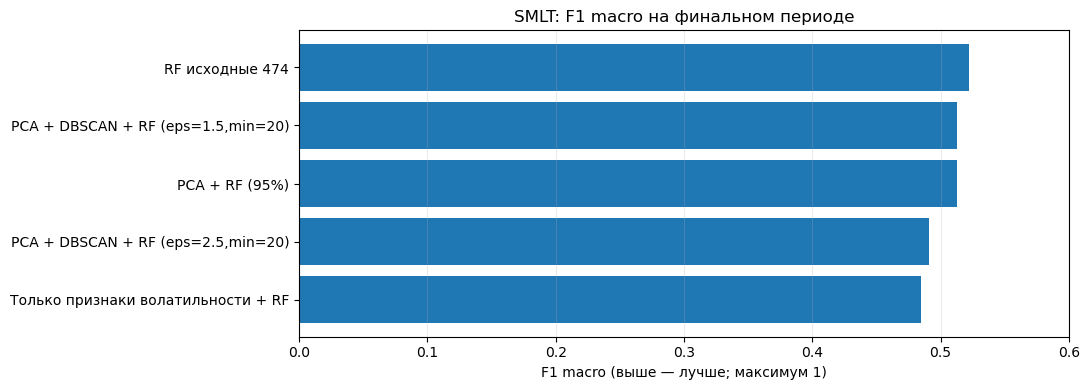

,метод,F1_macro,изменение_F1_macro_к_базе_п.п.,статус
0,RF исходные 474,0.521750,0.000000,OK
2,"PCA + DBSCAN + RF (eps=1.5,min=20)",0.512900,-0.884926,OK
1,PCA + RF (95%),0.512605,-0.914465,OK
3,"PCA + DBSCAN + RF (eps=2.5,min=20)",0.490653,-3.109702,OK
7,Только признаки волатильности + RF,0.484482,-3.726748,OK
4,LDA + логистическая регрессия,NaN,NaN,ERROR: NotImplementedError: transform not impl...
5,Взаимная информация + RF (k=50),NaN,NaN,ERROR: ValueError: invalid literal for int() w...
6,Взаимная информация + RF (k=100),NaN,NaN,ERROR: ValueError: invalid literal for int() w...


In [22]:
# Компактный CSV, русская таблица и графики.
out = pd.concat([validation_results, final_results], ignore_index=True, sort=False)
out.insert(0, "тикер", TICKER)
Path("research/afml/afml_05_regimes_pca/results").mkdir(parents=True, exist_ok=True); out.to_csv(Path("research/afml/afml_05_regimes_pca/results") / "JERICHON_AFML_05_PCA_DBSCAN_LDA_results.csv", index=False, encoding="utf-8-sig")
print("Сохранён: JERICHON_AFML_05_PCA_DBSCAN_LDA_results.csv")
display(out[["тикер","метод","этап","F1_macro","F1_класс_1","точность","полнота","сбалансированная_точность","статус"]])

plot_df = final_results[final_results["статус"] == "OK"].sort_values("F1_macro")
if not plot_df.empty:
    fig, ax = plt.subplots(figsize=(11, max(4, .55*len(plot_df))))
    ax.barh(plot_df["метод"], plot_df["F1_macro"])
    ax.set_title(f"{TICKER}: F1 macro на финальном периоде")
    ax.set_xlabel("F1 macro (выше — лучше; максимум 1)")
    ax.set_xlim(0, min(1, max(.1, plot_df["F1_macro"].max()*1.15)))
    ax.grid(axis="x", alpha=.25)
    plt.tight_layout()
    plt.show()

# Сравниваем с базовой моделью в процентах, но не объявляем победу по малой разнице.
base_row = final_results[(final_results["метод"] == "RF исходные 474") & (final_results["статус"] == "OK")]
if not base_row.empty:
    base_f1 = float(base_row.iloc[0]["F1_macro"])
    final_results["изменение_F1_macro_к_базе_п.п."] = 100*(final_results["F1_macro"] - base_f1)
    display(final_results[["метод","F1_macro","изменение_F1_macro_к_базе_п.п.","статус"]].sort_values("F1_macro", ascending=False))
